# Middlesex DA charges, 2017–2024: EDA

A short pass over the Middlesex data: audit the 8 yearly sheets, clean them, remove motor vehicle and civil records, and compare basic stats with and without them.

- **Unit:** each row is one **charge**. A **case** is one Case Number, and a case can have several charges.
- **Filter:** drop every *Motor Vehicle Other* case and every civil-infraction charge. Criminal MV cases (OUI, OUI serious bodily injury, MV homicide, MV serious bodily injury) stay. Details in 3.5.
- **Year:** `sheet_year`, which equals the year of Earliest Event Date.
- Outputs show counts only, never case numbers or defendant IDs.

The earlier, longer EDA (crime types, sentencing, demographics) is in `eda_middlesex_2017_2024_v1.ipynb`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

DATA_DIR = Path("../data/middlesex/raw")
CLEAN_DIR = Path("../data/middlesex/clean")
TODAY = pd.Timestamp.today().normalize()

pd.set_option("display.max_columns", 80, "display.width", 200, "display.max_rows", 120)

In [2]:
# Chart styling: reference palette (light mode), fixed categorical order.
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
OTHER = "#c3c2b7"
DARK_INK_ON = {"#eda100", OTHER}  # fills that need dark text instead of white
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#f4f8fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)
VERSION_COLORS = {"All": MUTED, "Filtered": SERIES[0]}  # all data is context, filtered data is the focus

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "legend.frameon": False, "figure.dpi": 110,
})
thousands = mticker.StrMethodFormatter("{x:,.0f}")


def hbar(values, title, xlabel="", colors=None, fmt="{:,.0f}"):
    """Sorted horizontal bar chart with value labels at the bar ends."""
    order = values.sort_values().index
    values = values.loc[order]
    if isinstance(colors, pd.Series):
        colors = colors.loc[order].tolist()
    fig, ax = plt.subplots(figsize=(9, 0.32 * len(values) + 1.2))
    ax.barh(values.index.astype(str), values, color=colors if colors is not None else SERIES[0],
            height=0.7, edgecolor=SURFACE, linewidth=2)
    for y, v in enumerate(values):
        ax.text(v, y, " " + fmt.format(v), va="center", fontsize=8, color=INK_2)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.xaxis.set_major_formatter(thousands)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.margins(x=0.12)
    return ax


def stacked_share(tbl, title, colors, min_label=0.06):
    """100% horizontal stacked bars: one bar per row of `tbl`, one segment per column."""
    shares = tbl.div(tbl.sum(axis=1), axis=0)
    fig, ax = plt.subplots(figsize=(10, 0.42 * len(shares) + 1.9))
    y = np.arange(len(shares))
    left = np.zeros(len(shares))
    for col in shares.columns:
        color = colors.get(col, OTHER)
        vals = shares[col].to_numpy()
        ax.barh(y, vals, left=left, color=color, height=0.72, edgecolor=SURFACE, linewidth=2, label=col)
        for yi, (l, v) in enumerate(zip(left, vals)):
            if v >= min_label:
                ax.text(l + v / 2, yi, f"{v:.0%}", ha="center", va="center", fontsize=8,
                        color=INK if color in DARK_INK_ON else "white")
        left += vals
    ax.set_yticks(y, [f"{i}  (n={int(n):,})" for i, n in zip(shares.index, tbl.sum(axis=1))])
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    ax.grid(False)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.legend(ncol=4, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=8, handlelength=1, borderaxespad=0.3)
    ax.set_title(title, pad=40)
    return ax


def end_label(ax, series, name):
    """Label a line at its last point, instead of a legend."""
    ax.annotate(name, (series.index[-1], series.iloc[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color=INK_2)

## 1. Load and per-year audit

Each sheet of the Numbers file was exported to one CSV (`2017.csv` … `2024.csv`). All values are read as text first, so nothing is silently converted.

In [3]:
files = sorted(DATA_DIR.glob("*.csv"))
raw = pd.concat([pd.read_csv(f, dtype=str).assign(sheet_year=int(f.stem)) for f in files], ignore_index=True)
print(f"{len(raw):,} rows from {len(files)} sheets, {raw.shape[1] - 1} columns each")

audit = raw.groupby("sheet_year").agg(
    charges=("Case Number", "size"),
    cases=("Case Number", "nunique"),
    defendants=("Defendant ID", "nunique"),
)
audit["charges_per_case"] = (audit.charges / audit.cases).round(2)
audit

366,858 rows from 8 sheets, 62 columns each


,charges,cases,defendants,charges_per_case
sheet_year,,,,
2017,54888,26136,21042,2.10
2018,51977,24538,19825,2.12
2019,51367,24164,19534,2.13
2020,33251,15085,12580,2.20
2021,40621,18757,15035,2.17
2022,43016,19757,15865,2.18
2023,46661,21811,17559,2.14
2024,45077,20735,16372,2.17


**Are the columns the same every year?** First the column names and their order, compared with 2017.

In [4]:
columns = {int(f.stem): list(pd.read_csv(f, nrows=0).columns) for f in files}
ref = columns[2017]
pd.DataFrame({
    year: {"columns": len(cols), "same names as 2017": set(cols) == set(ref), "same order as 2017": cols == ref}
    for year, cols in columns.items()
}).T

,columns,same names as 2017,same order as 2017
2017,62,True,True
2018,62,True,True
2019,62,True,True
2020,62,True,True
2021,62,True,True
2022,62,True,True
2023,62,True,True
2024,62,True,True


**Are the formats the same every year?** The share of non-empty values (%) that parse as a `YYYY-MM-DD` date or as a number. 100 everywhere means the format didn't change between sheets.

In [5]:
DATE_COLS = ["Offense Date", "Earliest Event Date", "Disposition Date", "Sentence Date"]
NUM_COLS = ["Criminal Count Number", "Defendant DOB Year", "Age At Offense"]

PARSERS = (
    {c: lambda v: pd.to_datetime(v, format="%Y-%m-%d", errors="coerce") for c in DATE_COLS}
    | {c: lambda v: pd.to_numeric(v, errors="coerce") for c in NUM_COLS}
)
formats = pd.DataFrame({
    c: raw.groupby("sheet_year")[c].agg(lambda s: parse(s.dropna()).notna().mean())
    for c, parse in PARSERS.items()
})
formats.mul(100).round(1).T

sheet_year,2017,2018,2019,2020,2021,2022,2023,2024
Offense Date,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
Earliest Event Date,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
Disposition Date,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
Sentence Date,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
Criminal Count Number,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
Defendant DOB Year,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
Age At Offense,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0


**What does a sheet hold?** Each sheet holds the cases whose Earliest Event Date fell in that year, and no case appears in two sheets. So the sheets are separate slices, not cumulative copies. Offense dates can be earlier: an offense in late 2016 often reaches court in 2017.

In [6]:
event_year = pd.to_datetime(raw["Earliest Event Date"], errors="coerce").dt.year
has_date = event_year.notna()
print(f"Earliest Event Date year = sheet year: {event_year[has_date].eq(raw.sheet_year[has_date]).mean():.1%} "
      f"of rows with a date ({(~has_date).sum()} rows have none)")
print("Case numbers in more than one sheet:", raw.groupby("Case Number").sheet_year.nunique().gt(1).sum())

Earliest Event Date year = sheet year: 100.0% of rows with a date (16 rows have none)
Case numbers in more than one sheet: 0


## 2. Missingness by year

The share of charges (%) with an empty value, for every column and sheet year, sorted from most to least complete. Sentencing fields are mostly empty by design: they're only filled in when a sentence was imposed.

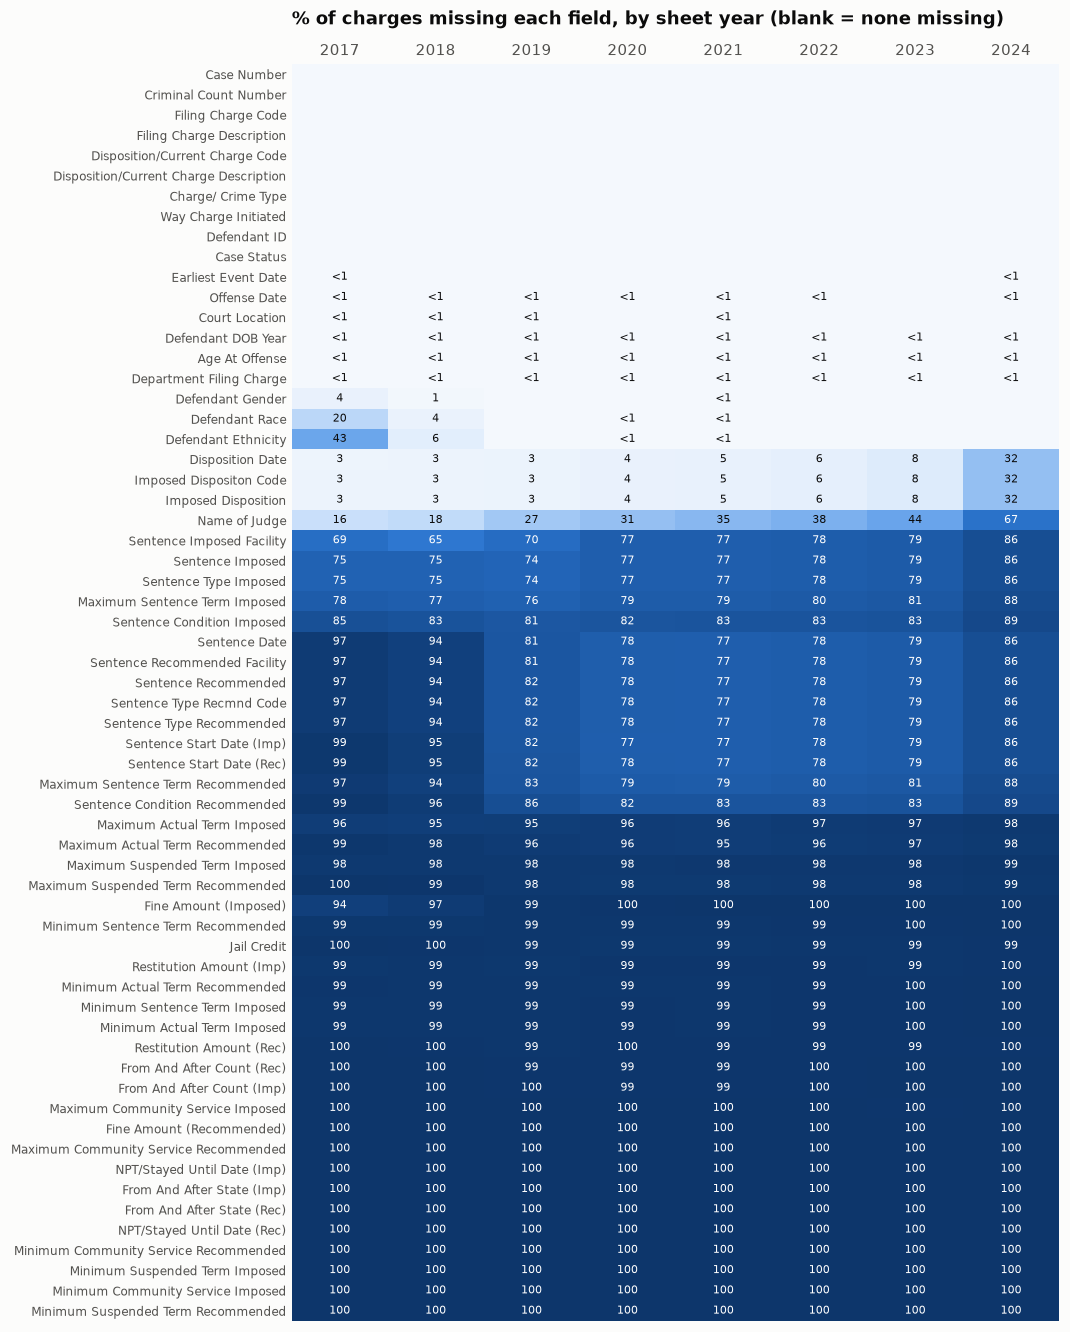

In [7]:
missing = raw.drop(columns="sheet_year").isna().groupby(raw.sheet_year).mean().mul(100).T
missing = missing.loc[missing.mean(axis=1).sort_values(kind="stable").index]

fig, ax = plt.subplots(figsize=(9, 0.22 * len(missing) + 1.2))
ax.imshow(missing, cmap=BLUES, vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(missing.shape[1]), missing.columns)
ax.set_yticks(range(len(missing)), missing.index, fontsize=8)
for (i, j), v in np.ndenumerate(missing.to_numpy()):
    label = "" if v == 0 else "<1" if v < 0.5 else f"{v:.0f}"
    ax.text(j, i, label, ha="center", va="center", fontsize=7, color="white" if v > 55 else INK)
ax.xaxis.tick_top()
ax.grid(False)
ax.tick_params(length=0)
for side in ax.spines.values():
    side.set_visible(False)
ax.set_title("% of charges missing each field, by sheet year (blank = none missing)", pad=26);

In [8]:
complete = missing.index[missing.max(axis=1) == 0]
nearly_empty = missing.index[missing.min(axis=1) >= 99]
print(f"Never empty in any year ({len(complete)}):", ", ".join(complete))
print(f"\nAt least 99% empty in every year ({len(nearly_empty)}):", ", ".join(nearly_empty))
print("\nColumns whose missingness moves by 5+ points between years:")
missing[(missing.max(axis=1) - missing.min(axis=1)) >= 5].round(1)

Never empty in any year (10): Case Number, Criminal Count Number, Filing Charge Code, Filing Charge Description, Disposition/Current Charge Code, Disposition/Current Charge Description, Charge/ Crime Type, Way Charge Initiated, Defendant ID, Case Status

At least 99% empty in every year (13): From And After Count (Rec), From And After Count (Imp), Maximum Community Service Imposed, Fine Amount (Recommended), Maximum Community Service Recommended, NPT/Stayed Until Date (Imp), From And After State (Imp), From And After State (Rec), NPT/Stayed Until Date (Rec), Minimum Community Service Recommended, Minimum Suspended Term Imposed, Minimum Community Service Imposed, Minimum Suspended Term Recommended

Columns whose missingness moves by 5+ points between years:


sheet_year,2017,2018,2019,2020,2021,2022,2023,2024
Defendant Race,19.8,3.5,0.0,0.0,0.0,0.0,0.0,0.0
Defendant Ethnicity,43.0,6.3,0.0,0.0,0.0,0.0,0.0,0.0
Disposition Date,2.6,2.8,3.3,4.0,4.6,5.5,8.3,31.6
Imposed Dispositon Code,2.8,2.8,3.3,4.0,4.6,5.5,8.3,31.6
Imposed Disposition,2.8,2.8,3.3,4.0,4.6,5.5,8.3,31.6
Name of Judge,15.6,17.9,27.0,31.0,34.8,38.4,44.0,67.4
Sentence Imposed Facility,69.2,64.8,70.3,77.0,77.3,78.1,79.1,86.0
Sentence Imposed,75.1,75.0,73.8,77.0,77.3,78.1,79.1,86.0
Sentence Type Imposed,75.1,75.0,73.8,77.0,77.3,78.1,79.1,86.0
Maximum Sentence Term Imposed,78.3,77.0,75.9,78.7,78.6,79.6,80.6,87.5


## 3. Cleaning

### 3.1 Duplicate rows

An **exact duplicate** matches another row in every column. Cleaning keeps one copy of each. The sample below hides Case Number and Defendant ID; copies of the same charge sit next to each other.

In [9]:
dupe_cols = raw.columns.drop("sheet_year")
is_dupe = raw.duplicated(subset=dupe_cols, keep=False)
extra = raw.duplicated(subset=dupe_cols)
print(f"{extra.sum():,} duplicate rows to remove ({is_dupe.sum():,} rows involved)")
print("By sheet year:", raw[extra].sheet_year.value_counts().sort_index().to_dict())

df = raw[~extra].copy()
print(f"{len(df):,} charges after removing duplicates")

(raw[is_dupe].sort_values(["Case Number", "Criminal Count Number"])
   [["sheet_year", "Criminal Count Number", "Filing Charge Description", "Court Location",
     "Earliest Event Date", "Imposed Disposition", "Case Status"]]
   .head(10))

53 duplicate rows to remove (96 rows involved)
By sheet year: {2017: 15, 2018: 6, 2019: 5, 2020: 2, 2021: 2, 2022: 11, 2023: 5, 2024: 7}
366,805 charges after removing duplicates


,sheet_year,Criminal Count Number,Filing Charge Description,Court Location,Earliest Event Date,Imposed Disposition,Case Status
1973,2017,1,RECEIVING STOLEN PROP $250 OR LESS,Natick District Court @ Framingham,2017-06-02,DISMISSED W/O PREJUDICE,Closed
1974,2017,1,RECEIVING STOLEN PROP $250 OR LESS,Natick District Court @ Framingham,2017-06-02,DISMISSED W/O PREJUDICE,Closed
1975,2017,1,RECEIVING STOLEN PROP $250 OR LESS,Natick District Court @ Framingham,2017-06-02,DISMISSED W/O PREJUDICE,Closed
1976,2017,1,RECEIVING STOLEN PROP $250 OR LESS,Natick District Court @ Framingham,2017-06-02,DISMISSED W/O PREJUDICE,Closed
108304,2019,1,VIOLATION OF STATE SANITARY CODE,Malden District Court,2019-11-01,DISMISSED W/O PREJUDICE LACK OF PROSECUTION,Closed
108305,2019,1,VIOLATION OF STATE SANITARY CODE,Malden District Court,2019-11-01,DISMISSED W/O PREJUDICE LACK OF PROSECUTION,Closed
108306,2019,1,VIOLATION OF STATE SANITARY CODE,Malden District Court,2019-11-01,DISMISSED W/O PREJUDICE LACK OF PROSECUTION,Closed
2216,2017,1,LARCENY BY CHECK,Somerville District Court,2017-02-14,NOLLE PROSEQUI,Closed
2217,2017,1,LARCENY BY CHECK,Somerville District Court,2017-02-14,NOLLE PROSEQUI,Closed
2218,2017,1,IDENTITY FRAUD,Somerville District Court,2017-02-14,NOLLE PROSEQUI,Closed


### 3.2 Types and typos

Parse dates and numbers, blank out impossible values, and merge two crime-type spellings.

In [10]:
fixes = {}
for c in DATE_COLS:
    parsed = pd.to_datetime(df[c], format="%Y-%m-%d", errors="coerce")
    ok = parsed.between("1950-01-01", TODAY)
    fixes[f"{c} outside 1950–today (blanked)"] = (parsed.notna() & ~ok).sum()
    df[c] = parsed.where(ok)

for c in NUM_COLS:
    df[c] = pd.to_numeric(df[c], errors="coerce")
bad_age = df["Age At Offense"].notna() & ~df["Age At Offense"].between(10, 100)
fixes["Age At Offense outside 10–100 (blanked)"] = bad_age.sum()
df.loc[bad_age, "Age At Offense"] = np.nan

CRIME_FIXES = {"Accessroy Before the Fact": "Accessory Before the Fact", "Larceny From Building": "Larceny from Building"}
fixes["Crime type misspellings (merged)"] = df["Charge/ Crime Type"].isin(CRIME_FIXES).sum()
df["Charge/ Crime Type"] = df["Charge/ Crime Type"].replace(CRIME_FIXES)

pd.Series(fixes, name="charges").to_frame()

,charges
Offense Date outside 1950–today (blanked),39
Earliest Event Date outside 1950–today (blanked),0
Disposition Date outside 1950–today (blanked),111
Sentence Date outside 1950–today (blanked),15
Age At Offense outside 10–100 (blanked),188
Crime type misspellings (merged),7


### 3.3 Date quality flags

Two date problems would make time to disposition wrong:

- **Offense after Earliest Event Date.** A case can't reach court before the offense, so one of the dates is wrong. Most look like a year typo in Earliest Event Date, for example an offense on 2018-01-02 with an event on 2017-01-03. These cases are probably in the wrong sheet too.
- **No Earliest Event Date.**

`date_flag` marks the whole case. Flagged cases stay in the data but are left out of time to disposition.

In [11]:
problem = pd.Series(
    np.select([df["Earliest Event Date"].isna(), df["Offense Date"] > df["Earliest Event Date"]],
              ["No event date", "Offense after event"], ""),
    index=df.index,
).replace("", np.nan)
df["date_flag"] = problem.groupby(df["Case Number"]).transform("first")

first_rows = df.drop_duplicates("Case Number")
pd.crosstab(first_rows.date_flag.fillna("OK"), first_rows.sheet_year, margins=True, margins_name="Total")

sheet_year,2017,2018,2019,2020,2021,2022,2023,2024,Total
date_flag,,,,,,,,,
No event date,7,0,0,0,0,0,0,1,8
OK,26024,24484,24112,15046,18687,19726,21776,20697,170552
Offense after event,105,54,52,39,70,31,35,37,423
Total,26136,24538,24164,15085,18757,19757,21811,20735,170983


### 3.4 Disposition groups

`Imposed Disposition` has dozens of raw values. They're grouped into 8 outcomes. The table lists every raw value with its group, so the outcome numbers below can be traced back.

In [12]:
DISP_ORDER = [
    "Guilty / delinquent", "CWOF", "Pretrial probation / diversion", "Dismissed",
    "Nolle prosequi", "Not guilty", "Civil infraction", "Other / none",
]
DISP_COLORS = dict(zip(DISP_ORDER[:-1], SERIES)) | {"Other / none": OTHER}


def disposition_group(d):
    if pd.isna(d):
        return "Other / none"
    d = d.upper()
    if d in ("RESPONSIBLE", "NOT RESPONSIBLE"):
        return "Civil infraction"
    if d.startswith(("NOT GUILTY", "NOT DELINQUENT", "NO BILL", "NO PROBABLE CAUSE")):
        return "Not guilty"
    if d.startswith(("CWOF", "CONTINUED W/O FINDING")):
        return "CWOF"
    if d.startswith(("PRE-TRIAL PROBATION", "DIVERSION")):
        return "Pretrial probation / diversion"
    if "GUILTY" in d or "DELINQUENT" in d:
        return "Guilty / delinquent"
    if d.startswith("NOLLE"):
        return "Nolle prosequi"
    if "DISMISS" in d:
        return "Dismissed"
    return "Other / none"


df["disp_group"] = pd.Categorical(df["Imposed Disposition"].map(disposition_group), DISP_ORDER, ordered=True)
print(f"{df['Imposed Disposition'].nunique()} raw values (plus empty) -> {len(DISP_ORDER)} groups")

(df.groupby(["disp_group", "Imposed Disposition"], observed=True, dropna=False).size()
   .rename("charges").reset_index().sort_values(["disp_group", "charges"], ascending=[True, False])
   .set_index(["disp_group", "Imposed Disposition"]))

71 raw values (plus empty) -> 8 groups


charges
disp_group                     Imposed Disposition                                        
Guilty / delinquent            GUILTY CHANGE OF PLEA                                 34333
                               GUILTY TRIAL                                           1686
                               GUILTY FILED                                           1494
                               GUILTY JURY TRIAL                                      1186
                               GUILTY CHANGE OF PLEA LESSER OFFENSE                   1113
                               DELINQUENT CHANGE OF PLEA                               425
                               GUILTY FINES                                            383
                               GUILTY BENCH TRIAL                                      245
                               GUILTY TRIAL LESSER INCLUDED                             66
                               GUILTY JURY TRIAL LESSER INCLUDED                        20
                               DELINQUENT TRIAL                                         13
                               DELINQUENT BENCH TRIAL                                   12
                               GUILTY BENCH TRIAL LESSER INCLUDED                        8
                               Guilty Jury Trial (and Bench) Lesser Included             7
                               DELINQUENT CHANGE OF PLEA LESSER OFFENSE                  6
                               DELINQUENT JURY TRIAL                                     5
CWOF                           CONTINUED W/O FINDING                                 26618
                               CONTINUED W/O FINDING LESSER OFFENSE                    183
                               CWOF AFTER TRIAL                                         29
                               CWOF AFTER TRIAL LESSER INCLUDED                          6
                               CWOF AFTER BENCH TRIAL LESSER INCLUDED                    3
                               CWOF AFTER JURY TRIAL                                     3
Pretrial probation / diversion PRE-TRIAL PROBATION                                   16360
                               PRE-TRIAL PROBATION LESSER OFFENSE                       17
                               DIVERSION PASS                                            5
Dismissed                      DISMISSED W/O PREJUDICE LACK OF PROSECUTION           44984
                               DISMISSED W/O  PREJUDICE                              30194
                               DISMISSED OUTRIGHT AT REQUEST OF CW (POST-ARR)        29422
                               DISMISSED ON COURT COSTS                              27260
                               DISMISSED OUTRIGHT AT REQUEST OF CW (PRIOR TO ARR)    12319
                               DISMISSED BY FINES                                    10900
                               DISMISSED BY COURT (POST-ARRAIGNMENT)                  2673
                               MOTION TO DISMISS ALLOWED                              2567
                               DISMISSED BY COURT (PRIOR TO ARRAIGNMENT)              2111
                               DISMISSED PRIOR TO ARRAIGNMENT                         1981
                               DISMISSED ON COMMUNITY SERVICE                          616
                               DISMISSED ON RESTITUTION                                317
                               DISMISSED PURSUANT TO ACCORD AND SATISFACTION           152
                               DISMISSED WITH PREJUDICE LACK OF PROSECUTION            140
Nolle prosequi                 NOLLE PROSEQUI                                        23831
Not guilty                     NOT GUILTY TRIAL                                       4276
                               NOT GUILTY JURY TRIAL                                  1346
                               NOT GUILTY BENCH TRIAL                          

### 3.5 Remove Motor Vehicle Other cases and civil charges

- **Motor Vehicle Other cases are dropped whole.** `Charge/ Crime Type` is recorded once per case, so every charge in the case goes. The legacy labels `MOTOR VEHICLE` and `OTHER MOTOR VEHICLE` count as MV Other.
- **Civil-infraction charges are dropped wherever they appear.** A charge is civil if its filing charge description contains ` * ` or its disposition is RESPONSIBLE / NOT RESPONSIBLE. A case with no charges left is dropped.
- **Kept:** OUI, OUI serious bodily injury, MV homicide and MV serious bodily injury cases, minus their civil charges (for example a marked-lanes violation on an OUI case).

MV Other cases aren't purely civil. Many of their charges are criminal, such as unlicensed operation or driving with a suspended license (see `charges − civil_charges` below), so dropping them is a scope choice.

In [13]:
crime = df["Charge/ Crime Type"]
is_mv = crime.str.upper().str.contains("MOTOR VEHICLE")  # doesn't match "Larceny MV" or "B&E/MV-Boat"
df["mv_other"] = is_mv & ~crime.str.contains("OUI|Homicide|Serious Bodily Injury", case=False)
df["civil"] = df["Filing Charge Description"].str.contains(r" \* ", regex=True) | df.disp_group.eq("Civil infraction")

after_mv = df[~df.mv_other]
clean = after_mv[~after_mv.civil].copy()

steps = pd.DataFrame(
    [(name, len(d), d["Case Number"].nunique()) for name, d in [
        ("After removing duplicates", df),
        ("Drop Motor Vehicle Other cases", after_mv),
        ("Drop civil charges", clean),
    ]],
    columns=["step", "charges", "cases"],
).set_index("step")
steps["charges removed"] = -steps.charges.diff()
steps["cases removed"] = -steps.cases.diff()
print(f"Kept {len(clean) / len(df):.1%} of charges and {steps.cases.iloc[-1] / steps.cases.iloc[0]:.1%} of cases")
steps.fillna(0).astype(int)

Kept 60.8% of charges and 65.3% of cases


,charges,cases,charges removed,cases removed
step,,,,
After removing duplicates,366805,170983,0,0
Drop Motor Vehicle Other cases,238518,111816,128287,59167
Drop civil charges,223071,111601,15447,215


**What was kept, by crime type.** Every MV crime type, plus all other crime types together.

In [14]:
group = pd.Series(np.where(is_mv, crime, "All non-MV crime types"), index=df.index)
kept = df.assign(kept=~df.mv_other & ~df.civil).groupby(group).agg(
    cases=("Case Number", "nunique"),
    charges=("Case Number", "size"),
    civil_charges=("civil", "sum"),
    charges_kept=("kept", "sum"),
)
kept["cases_kept"] = clean.groupby(group.loc[clean.index])["Case Number"].nunique()
kept.fillna(0).astype(int).sort_values("cases", ascending=False)[["cases", "cases_kept", "charges", "civil_charges", "charges_kept"]]

,cases,cases_kept,charges,civil_charges,charges_kept
All non-MV crime types,97931,97740,199931,3110,196821
Motor Vehicle Other,59165,0,128282,47227,0
Motor Vehicle OUI,13755,13731,38241,12263,25978
Motor Vehicle Homicide,80,80,197,36,161
Motor Vehicle Serious Bodily Injury,30,30,75,22,53
Motor Vehicle OUI Serious Bodily Injury,20,20,74,16,58
MOTOR VEHICLE,1,0,3,2,0
OTHER MOTOR VEHICLE,1,0,2,0,0


### 3.6 One row per case

Each case gets one outcome: the *most consequential* disposition among its charges, ranked
Guilty > CWOF > Pretrial probation / diversion > Not guilty > Nolle > Dismissed > Civil > Other / none.
A case with one guilty charge and two dismissed charges counts as *Guilty*. In the filtered data, outcomes come only from the charges that remain.

**Time to disposition** runs from Earliest Event Date to the case's last Disposition Date. It's only computed for closed cases without a date flag.

In [15]:
CASE_RANK = [
    "Guilty / delinquent", "CWOF", "Pretrial probation / diversion", "Not guilty",
    "Nolle prosequi", "Dismissed", "Civil infraction", "Other / none",
]


def build_cases(charges):
    """Collapse charge rows to one row per case."""
    rank = charges.disp_group.astype(str).map({g: i for i, g in enumerate(CASE_RANK)})
    out = charges.assign(_rank=rank).groupby("Case Number").agg(
        sheet_year=("sheet_year", "first"),
        crime_type=("Charge/ Crime Type", "first"),
        court=("Court Location", "first"),
        defendant=("Defendant ID", "first"),
        race=("Defendant Race", "first"),
        ethnicity=("Defendant Ethnicity", "first"),
        gender=("Defendant Gender", "first"),
        age=("Age At Offense", "min"),
        initiated=("Way Charge Initiated", "first"),
        status=("Case Status", "first"),
        date_flag=("date_flag", "first"),
        n_charges=("Case Number", "size"),
        offense_date=("Offense Date", "min"),
        event_date=("Earliest Event Date", "min"),
        last_disp_date=("Disposition Date", "max"),
        best_rank=("_rank", "min"),
    )
    out["court"] = out.court.fillna("Missing")
    out["case_outcome"] = pd.Categorical(out.pop("best_rank").map(dict(enumerate(CASE_RANK))), CASE_RANK, ordered=True)
    days = (out.last_disp_date - out.event_date).dt.days
    out["days_to_close"] = days.where(out.status.eq("Closed") & out.date_flag.isna() & days.ge(0))
    return out


cases_all = build_cases(df)
cases = build_cases(clean)
print(f"All: {len(cases_all):,} cases    Filtered: {len(cases):,} cases")
neg = cases_all.status.eq("Closed") & cases_all.date_flag.isna() & (cases_all.last_disp_date < cases_all.event_date)
print(f"Closed cases with a disposition before the earliest event (left out of time to disposition): {neg.sum()}")

All: 170,983 cases    Filtered: 111,601 cases
Closed cases with a disposition before the earliest event (left out of time to disposition): 364


## 4. Basic stats with and without MV Other and civil

**All** is the data after removing duplicates. **Filtered** also drops Motor Vehicle Other cases and civil charges (3.5). Outcomes are case-level (3.6). *Default* means the defendant didn't appear and the case is waiting on a warrant.

In [16]:
def basic_stats(charges, cases):
    outcome = cases.case_outcome.astype(str).value_counts(normalize=True)
    disp = charges.disp_group.astype(str).value_counts(normalize=True)
    status = cases.status.value_counts(normalize=True)
    return {
        "Charges": len(charges),
        "Cases": len(cases),
        "Defendants": charges["Defendant ID"].nunique(),
        "Charges per case, mean": cases.n_charges.mean(),
        "Charges per case, median": cases.n_charges.median(),
        "% cases guilty / delinquent": outcome.get("Guilty / delinquent", 0),
        "% cases CWOF": outcome.get("CWOF", 0),
        "% cases pretrial probation / diversion": outcome.get("Pretrial probation / diversion", 0),
        "% cases dismissed or nolle": outcome.get("Dismissed", 0) + outcome.get("Nolle prosequi", 0),
        "% cases not guilty": outcome.get("Not guilty", 0),
        "% charges dismissed or nolle": disp.get("Dismissed", 0) + disp.get("Nolle prosequi", 0),
        "% cases still open": status.get("Open", 0),
        "% cases in default": status.get("Default", 0),
        "Median days to disposition (closed cases)": cases.days_to_close.median(),
    }


stats = pd.DataFrame({"All": basic_stats(df, cases_all), "Filtered": basic_stats(clean, cases)})


def fmt(row):
    if row.name.startswith("%"):
        return row.map("{:.1%}".format)
    return row.map("{:.2f}".format if "mean" in row.name else "{:,.0f}".format)


def change(row):
    if row.name.startswith("%"):
        return f"{(row.Filtered - row.All) * 100:+.1f} pts"
    return f"{row.Filtered / row.All - 1:+.0%}"


stats.apply(fmt, axis=1).assign(Change=stats.apply(change, axis=1))

,All,Filtered,Change
Charges,"366,805","223,071",-39%
Cases,"170,983","111,601",-35%
Defendants,"106,948","67,612",-37%
"Charges per case, mean",2.15,2.00,-7%
"Charges per case, median",2,1,-50%
% cases guilty / delinquent,12.2%,16.6%,+4.5 pts
% cases CWOF,9.9%,13.2%,+3.3 pts
% cases pretrial probation / diversion,5.7%,7.2%,+1.5 pts
% cases dismissed or nolle,62.7%,50.5%,-12.2 pts
% cases not guilty,2.2%,3.2%,+1.0 pts


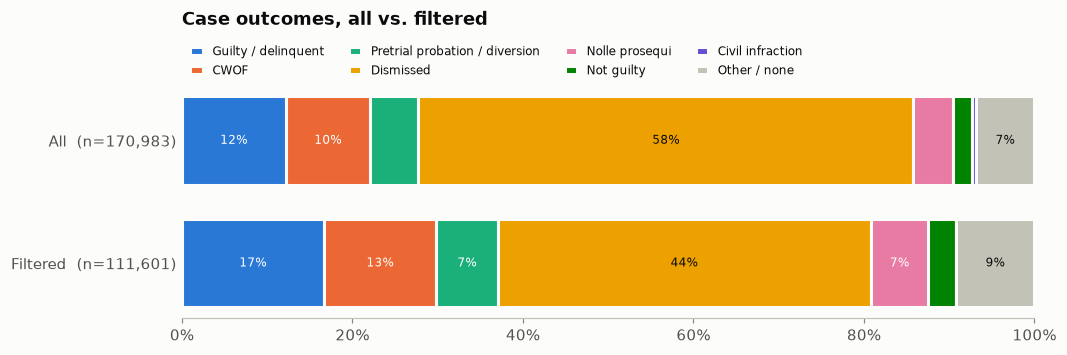

In [17]:
mix = pd.DataFrame({
    "All": cases_all.case_outcome.astype(str).value_counts(),
    "Filtered": cases.case_outcome.astype(str).value_counts(),
}).T.reindex(columns=DISP_ORDER, fill_value=0).fillna(0)
stacked_share(mix, "Case outcomes, all vs. filtered", DISP_COLORS);

**By sheet year.** The same two headline rates for each year, with the share of cases still open.

All                             Filtered                            
           % guilty % dismissed or nolle % open % guilty % dismissed or nolle % open
sheet_year                                                                          
2017           15.3                 61.1    0.2     21.2                 48.1    0.1
2018           15.4                 62.3    0.0     20.9                 50.0    0.1
2019           14.1                 63.1    0.1     19.5                 50.2    0.2
2020           11.5                 66.6    0.2     15.7                 56.3    0.3
2021           11.2                 66.0    0.5     15.6                 55.6    0.8
2022           10.4                 66.4    1.0     14.3                 55.7    1.5
2023           10.0                 65.6    3.0     14.3                 52.6    4.5
2024            7.4                 52.4   22.9      9.4                 39.3   30.4

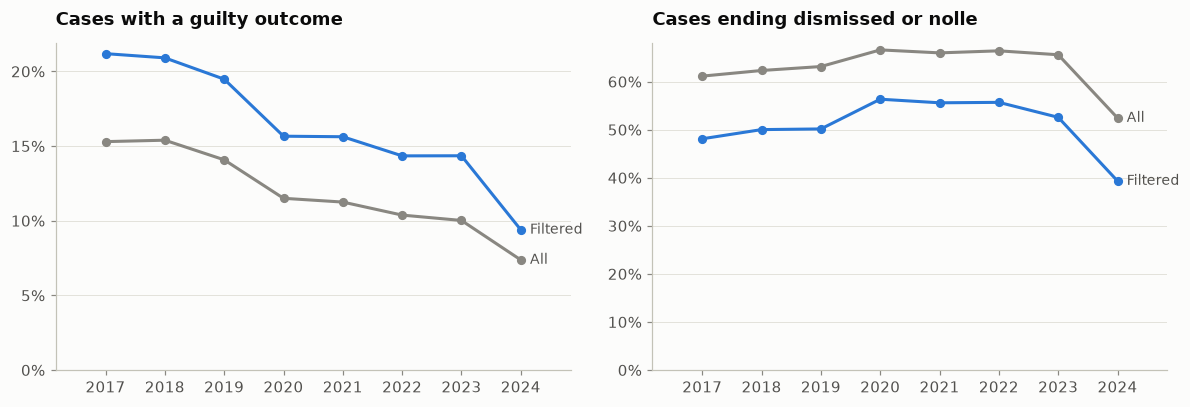

In [18]:
def yearly(cases):
    outcome = cases.case_outcome.astype(str)
    return pd.DataFrame({
        "% guilty": outcome.eq("Guilty / delinquent").groupby(cases.sheet_year).mean(),
        "% dismissed or nolle": outcome.isin(["Dismissed", "Nolle prosequi"]).groupby(cases.sheet_year).mean(),
        "% open": cases.status.eq("Open").groupby(cases.sheet_year).mean(),
    })


by_year = {"All": yearly(cases_all), "Filtered": yearly(cases)}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, title in zip(axes, ["% guilty", "% dismissed or nolle"],
                          ["Cases with a guilty outcome", "Cases ending dismissed or nolle"]):
    for name, t in by_year.items():
        ax.plot(t.index, t[col], marker="o", markersize=5, color=VERSION_COLORS[name])
        end_label(ax, t[col], name)
    ax.yaxis.set_major_locator(mticker.MultipleLocator(0.05 if col == "% guilty" else 0.1))
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
    ax.set_ylim(0, None)
    ax.set_title(title)
    ax.margins(x=0.12)
fig.tight_layout()

pd.concat(by_year, axis=1).mul(100).round(1)

**The latest years are incomplete.** Open cases have no final outcome yet, so 2023–2024 rates will shift as those cases close. Compare 2024 with earlier years carefully, and only use closed cases for time to disposition.

## 5. Charges per case

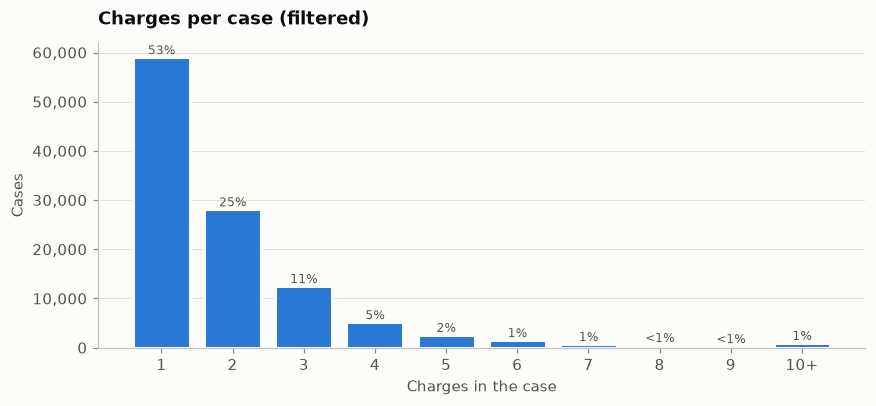

In [19]:
dist = cases.n_charges.clip(upper=10).value_counts().sort_index()
dist.index = [str(i) if i < 10 else "10+" for i in dist.index]

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(dist.index, dist, color=SERIES[0], edgecolor=SURFACE, linewidth=2)
for x, v in enumerate(dist):
    share = v / dist.sum()
    ax.text(x, v, f"{share:.0%}" if share >= 0.005 else "<1%", ha="center", va="bottom", fontsize=8, color=INK_2)
ax.yaxis.set_major_formatter(thousands)
ax.set_xlabel("Charges in the case")
ax.set_ylabel("Cases")
ax.set_title("Charges per case (filtered)");

In [20]:
pd.DataFrame({
    "All, mean": cases_all.groupby("sheet_year").n_charges.mean(),
    "Filtered, mean": cases.groupby("sheet_year").n_charges.mean(),
    "Filtered, median": cases.groupby("sheet_year").n_charges.median(),
    "Filtered, % with 1 charge": cases.n_charges.eq(1).groupby(cases.sheet_year).mean() * 100,
    "Filtered, max": cases.groupby("sheet_year").n_charges.max(),
}).round(2)

,"All, mean","Filtered, mean","Filtered, median","Filtered, % with 1 charge","Filtered, max"
sheet_year,,,,,
2017,2.10,1.96,1.0,54.45,68
2018,2.12,1.98,1.0,54.28,176
2019,2.13,2.00,1.0,52.91,98
2020,2.20,2.07,1.0,50.27,77
2021,2.17,2.02,1.0,52.07,33
2022,2.18,2.03,1.0,51.92,41
2023,2.14,1.97,1.0,53.71,60
2024,2.17,1.99,1.0,52.28,87


## 6. Volume over time

Cases per month, dated by Earliest Event Date. The shaded band marks the spring 2020 COVID-19 court restrictions, when most in-person court business stopped.

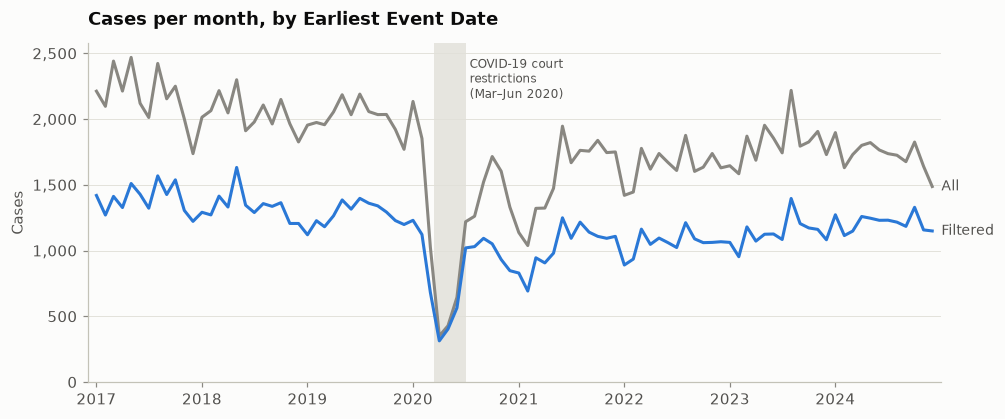

In [21]:
def monthly_cases(cases):
    m = cases.groupby(cases.event_date.dt.to_period("M")).size()
    m.index = m.index.to_timestamp()
    return m


monthly = pd.DataFrame({"All": monthly_cases(cases_all), "Filtered": monthly_cases(cases)})

fig, ax = plt.subplots(figsize=(10, 4))
ax.axvspan(pd.Timestamp("2020-03-15"), pd.Timestamp("2020-07-01"), color=GRID, alpha=0.8, lw=0)
ax.text(pd.Timestamp("2020-07-15"), monthly.to_numpy().max(), "COVID-19 court\nrestrictions\n(Mar–Jun 2020)",
        fontsize=8, color=INK_2, va="top")
for name in monthly:
    ax.plot(monthly.index, monthly[name], color=VERSION_COLORS[name])
    end_label(ax, monthly[name], name)
ax.yaxis.set_major_formatter(thousands)
ax.set_ylim(0, None)
ax.set_ylabel("Cases")
ax.set_title("Cases per month, by Earliest Event Date")
ax.margins(x=0.01);

In [22]:
totals = pd.DataFrame({
    "All cases": cases_all.groupby("sheet_year").size(),
    "Filtered cases": cases.groupby("sheet_year").size(),
})
totals["% kept"] = (totals["Filtered cases"] / totals["All cases"] * 100).round(1)
totals["Filtered vs. 2019"] = (totals["Filtered cases"] / totals.loc[2019, "Filtered cases"] - 1).map("{:+.0%}".format)
totals

,All cases,Filtered cases,% kept,Filtered vs. 2019
sheet_year,,,,
2017,26136,16749,64.1,+9%
2018,24538,16042,65.4,+5%
2019,24164,15308,63.4,+0%
2020,15085,10287,68.2,-33%
2021,18757,12359,65.9,-19%
2022,19757,12703,64.3,-17%
2023,21811,13617,62.4,-11%
2024,20735,14536,70.1,-5%


## 7. Cases by court

Colored by court type, since other counties' extracts may not include Superior or Juvenile courts. `% removed` is the share of a court's cases dropped by the MV Other / civil filter.

,All cases,Filtered cases,% removed
court,,,
Lowell District Court,41911,29208,30.3
Malden District Court,17324,11562,33.3
Framingham District Court,15911,10101,36.5
Cambridge District Court,13147,9634,26.7
Woburn District Court,15192,8964,41.0
Waltham District Court,11024,7464,32.3
Somerville District Court,10136,7050,30.4
Marlborough District Court,9591,5516,42.5
Ayer District Court,11106,5199,53.2


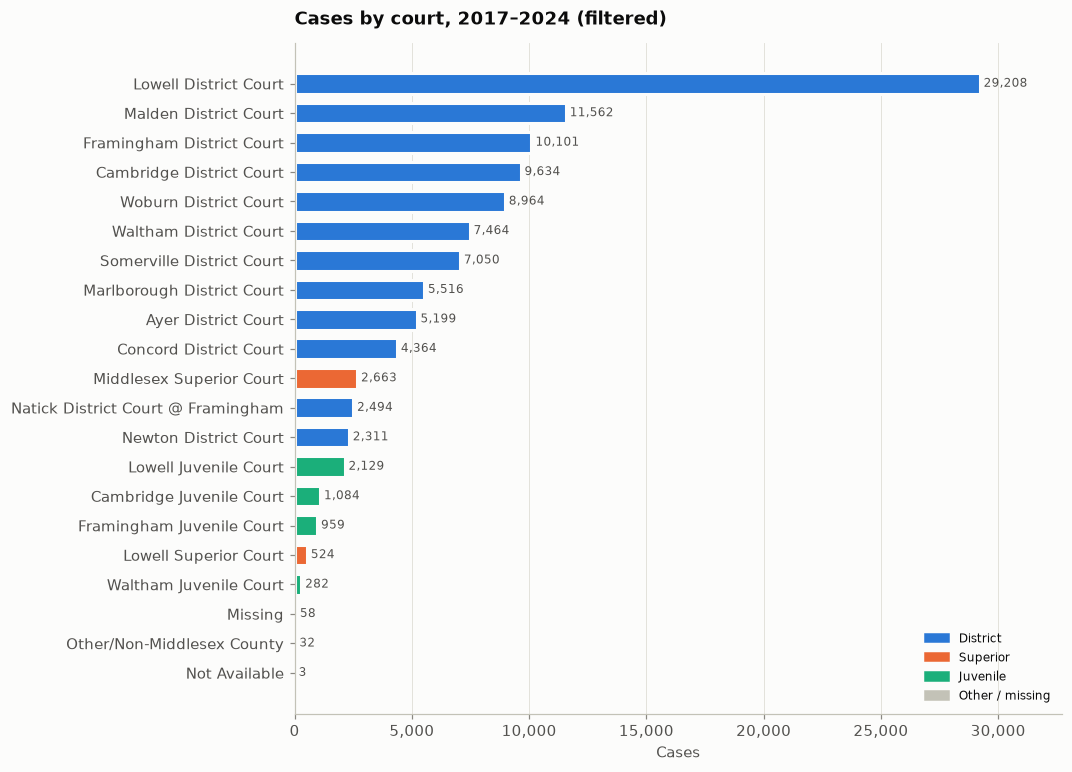

In [23]:
courts = pd.DataFrame({
    "All cases": cases_all.court.value_counts(),
    "Filtered cases": cases.court.value_counts(),
}).fillna(0).astype(int).sort_values("Filtered cases", ascending=False)
courts["% removed"] = ((1 - courts["Filtered cases"] / courts["All cases"]) * 100).round(1)

COURT_TYPE_COLORS = {"District": SERIES[0], "Superior": SERIES[1], "Juvenile": SERIES[2], "Other / missing": OTHER}
court_type = courts.index.to_series().str.extract("(District|Superior|Juvenile)")[0].fillna("Other / missing")
ax = hbar(courts["Filtered cases"], "Cases by court, 2017–2024 (filtered)", xlabel="Cases",
          colors=court_type.map(COURT_TYPE_COLORS))
ax.legend(handles=[Patch(color=c, label=t) for t, c in COURT_TYPE_COLORS.items()], loc="lower right", fontsize=8)
courts

In [24]:
pd.crosstab(cases.court, cases.sheet_year, margins=True, margins_name="Total").sort_values("Total", ascending=False)

sheet_year,2017,2018,2019,2020,2021,2022,2023,2024,Total
court,,,,,,,,,
Total,16749,16042,15308,10287,12359,12703,13617,14536,111601
Lowell District Court,4283,4399,3924,2704,3106,3308,3704,3780,29208
Malden District Court,1609,1653,1686,1143,1237,1380,1412,1442,11562
Framingham District Court,1532,1333,1429,1001,1189,1131,1187,1299,10101
Cambridge District Court,1332,1231,1291,797,1049,1138,1226,1570,9634
Woburn District Court,1396,1346,1209,729,1079,1123,1043,1039,8964
Waltham District Court,950,1016,979,745,837,875,1023,1039,7464
Somerville District Court,1133,1127,1125,538,695,688,833,911,7050
Marlborough District Court,746,719,770,585,622,626,710,738,5516


## 8. Save the cleaned data

Both files go to `fa26/data/middlesex/clean/`. Like the raw CSVs, they contain case numbers and defendant IDs.

- **`charges.csv`:** filtered charges, one row per charge, with all original columns plus `sheet_year`, `disp_group` and `date_flag`.
- **`cases.csv`:** filtered cases, one row per Case Number, from `build_cases` (outcome, court, demographics, dates, `days_to_close`).

In [25]:
CLEAN_DIR.mkdir(exist_ok=True)
clean.drop(columns=["mv_other", "civil"]).to_csv(CLEAN_DIR / "charges.csv", index=False)
cases.to_csv(CLEAN_DIR / "cases.csv")

for name, expected in [("charges.csv", len(clean)), ("cases.csv", len(cases))]:
    n = len(pd.read_csv(CLEAN_DIR / name, dtype=str))
    print(f"{name}: {n:,} rows (expected {expected:,})")

charges.csv: 223,071 rows (expected 223,071)
cases.csv: 111,601 rows (expected 111,601)


## Key takeaways

- **The sheets are consistent and separate.** All 8 have the same 62 columns in the same order, with the same date and number formats. Each sheet holds the cases whose Earliest Event Date fell in that year, and no case appears in two sheets.
- **Missingness to watch:**
  - Race and ethnicity are missing for 20% and 43% of 2017 charges (4% and 6% in 2018), then complete.
  - Disposition is missing for 32% of 2024 charges because many of those cases are still open.
  - Judge name gets less complete every year (16% missing in 2017, 67% in 2024).
  - Sentencing fields are mostly empty by design.
- **Cleaning:** 53 exact duplicate rows removed. 431 cases flagged for bad dates (423 with the offense after Earliest Event Date, 8 with no event date) and left out of time to disposition.
- **The filter removes about a third of cases.** It leaves 111,601 of 170,983 cases (65%) and 223,071 of 366,805 charges (61%). Almost all of the drop is Motor Vehicle Other (59,167 cases). Civil charges elsewhere remove only 215 more cases.
- **The filter changes the headline numbers a lot,** so always say which version a number comes from:
  - Cases with a guilty outcome: 12.2% → 16.6%.
  - Cases ending dismissed or nolle: 62.7% → 50.5%.
  - Median days to disposition: 100 → 172, because MV Other cases close quickly.
- **Guilty outcomes decline over time** in both versions, from 21% of filtered cases in 2017 to 14% in 2023. 2024 is lower again, but 30% of filtered 2024 cases are still open.
- **Volume hasn't recovered from COVID-19.** Filtered cases fell 33% in 2020 compared with 2019, and 2024 was still 5% below 2019.
- **Courts:**
  - Lowell District Court has 26% of filtered cases.
  - The filter removes very different shares by court: over half of Ayer and Concord cases, but under 1% of Superior Court cases.
  - Superior and juvenile courts are about 7% of filtered cases. Check whether other counties' data include them.